<a href="https://colab.research.google.com/github/Muskan-Sh-23/Machine-learning/blob/main/Decision_Tree/DecisionTreeRegressor_from_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regression Tree

In [49]:
#Libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

## Dataset

For this implementation, we used the **California Housing Dataset**, a well-known regression dataset available through `sklearn`.

The dataset contains **20,640 samples** with **8 features** related to housing and demographic information, such as:

- Median Income
- House Age
- Average Rooms
- Average Bedrooms
- Population
- Average Occupancy
- Latitude
- Longitude

The target variable is the **median house value**.

This dataset is well suited for Decision Tree Regression because the target is **continuous**, making it a natural regression problem. It also contains multiple features with potentially nonlinear relationships with house value, allowing the decision tree to learn different prediction regions through feature-based splits.

It provides a realistic dataset for understanding how a regression tree finds splits and produces predictions without relying on a pre-built tree implementation.

In [50]:
from sklearn.datasets import fetch_california_housing   #dataset

data = fetch_california_housing()
df = pd.DataFrame(data.data, columns=data.feature_names)

df["Target"] = data.target

df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


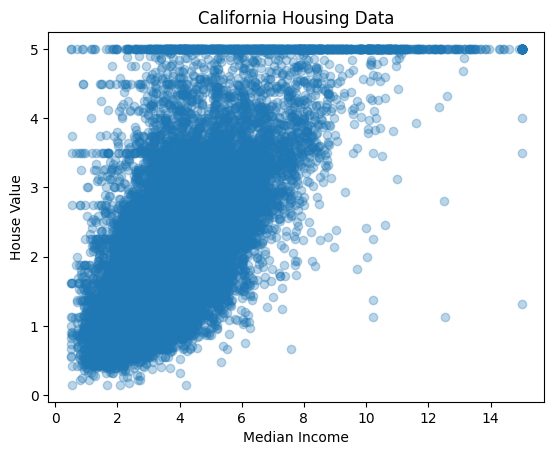

In [51]:
#Visualizing the datset
plt.scatter(X[:, 0], y, alpha=0.3)

plt.xlabel("Median Income")
plt.ylabel("House Value")
plt.title("California Housing Data")

plt.show()

In [52]:
X = data.data
y = data.target


In [53]:
print(X.shape)
print(y.shape)
print(data.feature_names)

(20640, 8)
(20640,)
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [54]:
# Train-Test Splitting
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [55]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [56]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

In [57]:
def calculate_sse(y):  # Calculating Sum of Squared Errors
    mean = np.mean(y)
    return np.sum((y - mean) ** 2)

In [58]:
def split_data(X, y, feature, threshold):
    left_mask = X[:, feature] <= threshold
    right_mask = X[:, feature] > threshold

    y_left = y[left_mask]
    y_right = y[right_mask]

    return y_left, y_right

In [59]:
def split_data(X, y, feature, threshold):
    left_mask = X[:, feature] <= threshold
    right_mask = X[:, feature] > threshold

    return X[left_mask], y[left_mask], X[right_mask], y[right_mask]

In [60]:
def split_sse(y_left, y_right):
    return calculate_sse(y_left) + calculate_sse(y_right)

In [61]:
def best_split(X, y):
    best_sse = float("inf")
    best_feature = None
    best_threshold = None

    n_features = X.shape[1]

    for feature in range(n_features):
        thresholds = np.unique(X[:, feature])

        for threshold in thresholds:
            _, y_left, _, y_right = split_data(X, y, feature, threshold)

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            sse = split_sse(y_left, y_right)

            if sse < best_sse:
                best_sse = sse
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold, best_sse

In [62]:
def build_tree(X, y, depth=0, max_depth=5):
    if depth >= max_depth or len(y) <= 1:
        return Node(value=np.mean(y))

    feature, threshold, sse = best_split(X, y)

    if feature is None:
        return Node(value=np.mean(y))

    X_left, y_left, X_right, y_right = split_data(
        X, y, feature, threshold
    )

    left = build_tree(X_left, y_left, depth + 1, max_depth)
    right = build_tree(X_right, y_right, depth + 1, max_depth)

    return Node(
        feature=feature,
        threshold=threshold,
        left=left,
        right=right
    )

In [63]:
def predict_one(x, node):
    if node.value is not None:
        return node.value

    if x[node.feature] <= node.threshold:
        return predict_one(x, node.left)
    else:
        return predict_one(x, node.right)
def predict(X, tree):
    return np.array([predict_one(x, tree) for x in X])

In [64]:
tree = build_tree(X_train, y_train, max_depth=5)

In [65]:
y_pred = predict(X_test, tree)

In [66]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("R² Score:", r2)

Mean Squared Error: 0.5245146178314738
R² Score: 0.5997321244428704


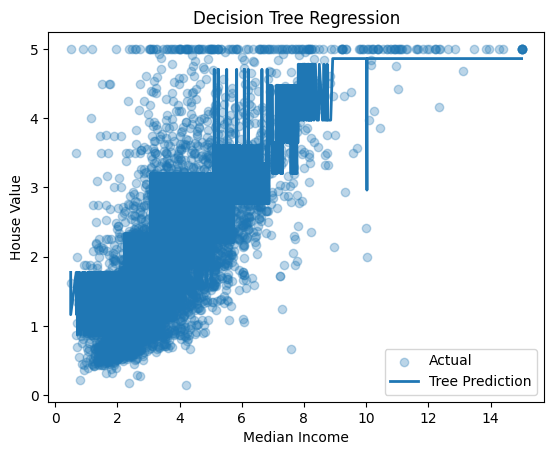

In [67]:
plt.scatter(X_test[:, 0], y_test, alpha=0.3, label="Actual")

sorted_idx = np.argsort(X_test[:, 0])

plt.plot(
    X_test[sorted_idx, 0],
    y_pred[sorted_idx],
    linewidth=2,
    label="Tree Prediction"
)

plt.xlabel("Median Income")
plt.ylabel("House Value")
plt.title("Decision Tree Regression")
plt.legend()
plt.show()

## Decision Tree Visualization

The visualization below shows the **actual structure of our Decision Tree Regressor built from scratch**.

Each internal node represents a **feature and threshold used to split the data**, while each leaf node represents the **mean target value used as the final prediction**.

The tree is structured hierarchically from the **root node at the top to the leaf predictions at the bottom**, showing how the model recursively divides the dataset to reduce prediction error.

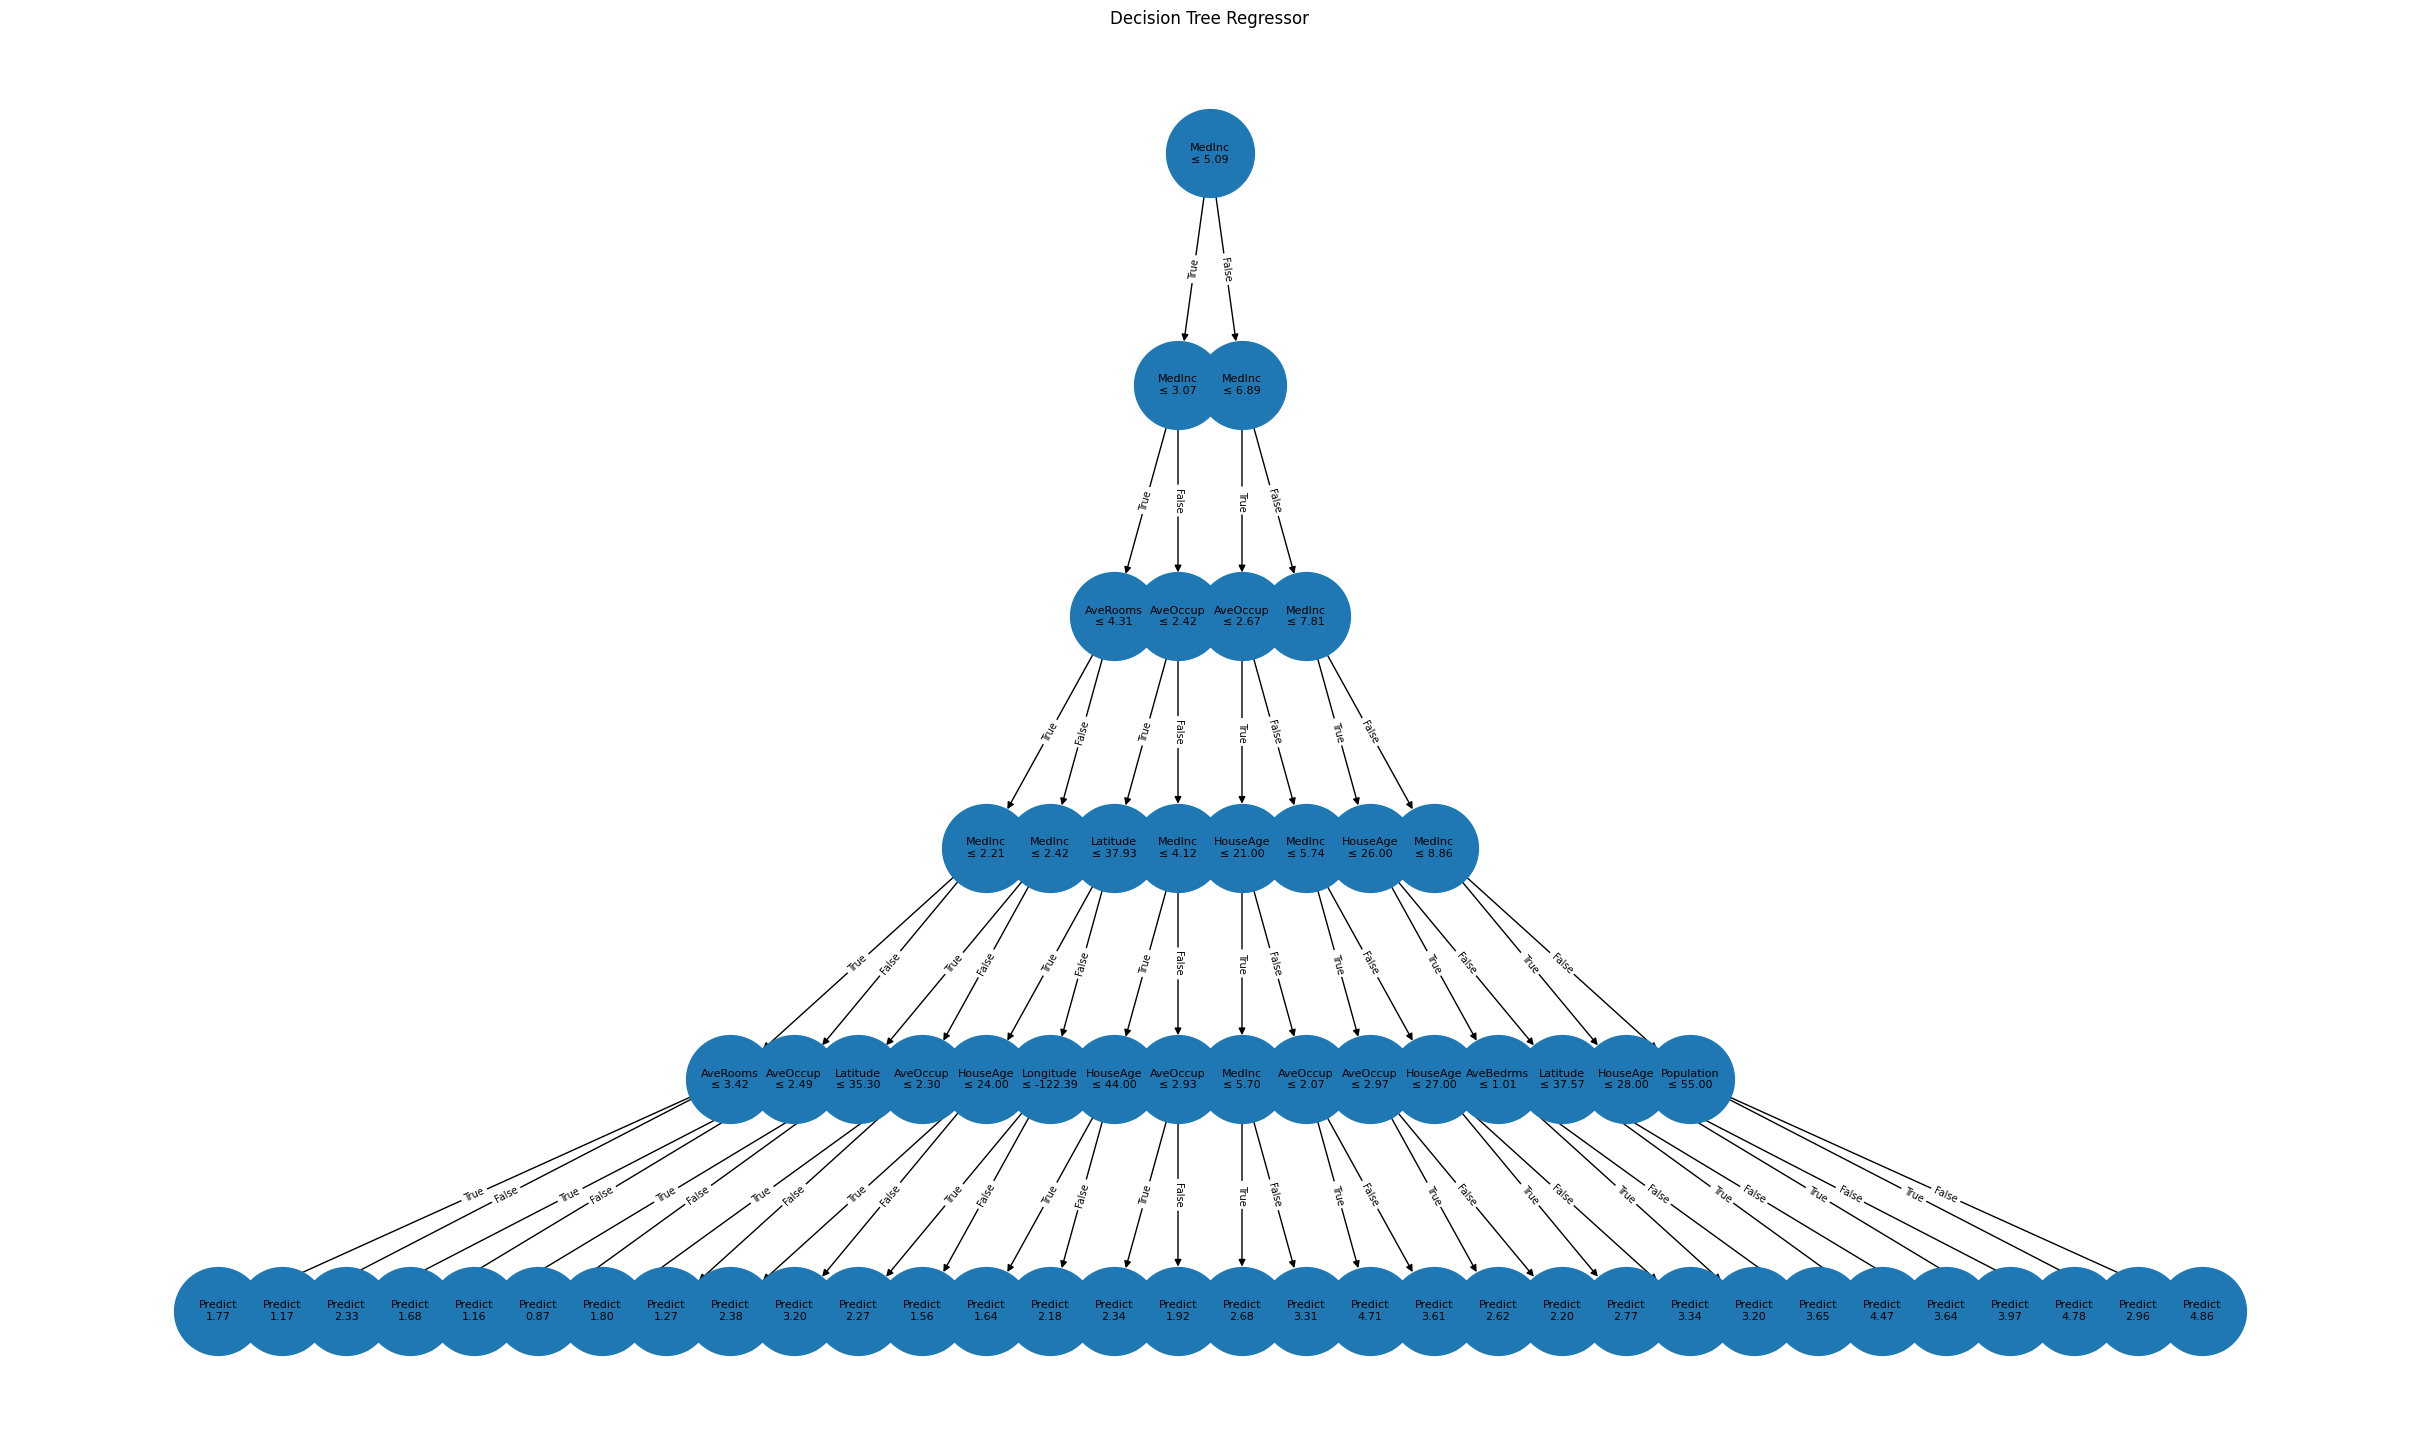

In [69]:
#Visualizing the TREE
def visualize_tree(node):

    graph = nx.DiGraph()
    labels = {}
    depths = {}
    counter = [0]

    def add_node(node, parent=None, edge_label="", depth=0):
        node_id = counter[0]
        counter[0] += 1

        depths[node_id] = depth

        if node.value is not None:
            labels[node_id] = f"Predict\n{node.value:.2f}"
        else:
            feature_name = data.feature_names[node.feature]
            labels[node_id] = f"{feature_name}\n≤ {node.threshold:.2f}"

        graph.add_node(node_id)

        if parent is not None:
            graph.add_edge(parent, node_id, label=edge_label)

        if node.value is None:
            add_node(node.left, node_id, "True", depth + 1)
            add_node(node.right, node_id, "False", depth + 1)

        return node_id

    add_node(node)

    # Find positions using tree depth
    positions = {}

    levels = {}
    for node_id, depth in depths.items():
        levels.setdefault(depth, []).append(node_id)

    for depth, nodes in levels.items():
        width = len(nodes)

        for i, node_id in enumerate(nodes):
            x = (i - (width - 1) / 2)
            positions[node_id] = (x, -depth)

    plt.figure(figsize=(24, 14))

    nx.draw(
        graph,
        positions,
        labels=labels,
        with_labels=True,
        node_size=4000,
        font_size=8,
        arrows=True
    )

    edge_labels = nx.get_edge_attributes(graph, "label")

    nx.draw_networkx_edge_labels(
        graph,
        positions,
        edge_labels=edge_labels,
        font_size=7
    )

    plt.title("Decision Tree Regressor")
    plt.axis("off")
    plt.show()
visualize_tree(tree)

## Decision Tree Regression — Conclusion

In this implementation, we built a **Decision Tree Regressor from scratch** using NumPy.

The tree:
- Searches through different features and thresholds to find the best split.
- Uses **Sum of Squared Errors (SSE)** to evaluate each split.
- Recursively creates left and right branches.
- Uses the **mean target value** as the prediction at each leaf.
- Limits the tree depth using `max_depth`.

### Results

Our Decision Tree Regression model achieved:

- **Mean Squared Error (MSE):** 0.5245
- **R² Score:** 0.5997

An R² score of approximately **0.60** means the model explains around **60% of the variation in the target values** on the test data.

This implementation helped us understand how a regression tree chooses splits, recursively builds its structure, and makes predictions without relying on a pre-built decision tree algorithm.